# D_01 · Lista de inscritos del circuito y cruce con carreras (Issue #8)

Issue #8 (Persona D). Usa las funciones de `src/inscritos.py` (descarga con `descargar()`,
lectura por cabecera y comprobacion del total) y `src/cruce.py` (cruce con las carreras
reutilizando `nombre_completo()` y `normalizar_nombre()` de `src/ligazon.py`).

1. **Descargar y revisar la lista de inscritos** en `datos/raw/inscritos/` y `datos/interim/inscritos.csv`.
2. **Comprobar la calidad de los inscritos** (total frente a la web, `pagado`, `estado` y dorsales unicos).
3. **Cruzar las participaciones de las carreras** contra inscritos y analizar los casos dudosos (`ambos`, `solo_nombre`, `solo_dorsal`, `ninguno`).

> En este notebook **nunca se muestran nombres ni dorsales**: solo recuentos y tablas pasadas por `quitar_identificadores()`.

In [1]:
import json
import sys
from pathlib import Path

# Si el notebook arranca dentro de la carpeta notebooks/, subimos un nivel para ver src/
ruta_raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ruta_raiz) not in sys.path:
    sys.path.insert(0, str(ruta_raiz))

import matplotlib.pyplot as plt
import pandas as pd

from src import obtencion
from src.config import DIR_INTERIM, FECHA_CORTE
from src.cruce import (
    RUTA_RESUMEN_CRUCE,
    buscar_archivos_carreras,
    clasificar_cruce,
    ejecutar_cruce_carreras,
    marcar_inscritos,
)
from src.inscritos import (
    RUTA_CSV_INSCRITOS,
    RUTA_RESUMEN_INSCRITOS,
    construir_inscritos_csv,
    descargar_inscritos,
)
from src.ligazon import nombre_completo, normalizar_nombre
from src.proteccion import (
    PALETA_COLORES,
    configurar_estilo_graficas,
    guardar_figura,
    quitar_identificadores,
)

# Ponemos el estilo de graficas comun para todo el equipo
configurar_estilo_graficas()

archivos_carreras = buscar_archivos_carreras()

print("Carpeta raiz:", ruta_raiz.name)
print("Fecha de corte del equipo (FECHA_CORTE):", FECHA_CORTE)
print("Existe inscritos.csv?:", RUTA_CSV_INSCRITOS.exists())
print("Carreras encontradas en interim/:", [archivo.name for archivo in archivos_carreras])

Carpeta raiz: p2-coruna-corre
Fecha de corte del equipo (FECHA_CORTE): 2026-11-22
Existe inscritos.csv?: True
Carreras encontradas en interim/: ['carrera_01.csv', 'carrera_02.csv', 'carrera_03.csv', 'carrera_04.csv', 'carrera_05.csv', 'carrera_06.csv']


## 1. Descarga y revision de la lista de inscritos (Parte 1)

En este primer bloque ejecutamos el flujo de `src/inscritos.py` para asegurarnos de que el notebook es reproducible de principio a fin:

- Llamamos a `descargar_inscritos()` midiendo cuantas peticiones reales se hacen a internet (si las paginas ya estan guardadas en `datos/raw/inscritos/`, el contador debe quedar a **0**, igual que en `02_carreras.ipynb`).
- Generamos `datos/interim/inscritos.csv` y su resumen de control `inscritos_resumen.json`.
- Revisamos el numero total de inscritos, los valores vacios, la columna `estado` y una muestra de las primeras filas pasada siempre por `quitar_identificadores()`.

In [2]:
# Contamos cuantas peticiones reales a la web se hacen al lanzar la descarga otra vez
peticiones_nuevas = 0
get_original = obtencion._sesion.get

def get_con_contador(*args, **kwargs):
    global peticiones_nuevas
    peticiones_nuevas += 1
    return get_original(*args, **kwargs)

# Cambiamos temporalmente el metodo get por el nuestro y luego lo dejamos como estaba
obtencion._sesion.get = get_con_contador
try:
    descargar_inscritos()
finally:
    obtencion._sesion.get = get_original

print("Peticiones nuevas a la web en esta ejecucion:", peticiones_nuevas)

# Construimos el CSV y el JSON de resumen desde las paginas guardadas en disco
construir_inscritos_csv()

# Leemos el JSON de resumen para comprobar que el total cuadra con la web
resumen_inscritos = json.loads(RUTA_RESUMEN_INSCRITOS.read_text(encoding="utf-8"))
print("\nResumen de control (inscritos_resumen.json):")
print(json.dumps(resumen_inscritos, indent=2, ensure_ascii=False))

# Cargamos la tabla de inscritos como texto para que no se pierdan ceros ni formatos
tabla_inscritos = pd.read_csv(RUTA_CSV_INSCRITOS, dtype=str).fillna("")

vacios_por_columna = (tabla_inscritos == "").sum().to_dict()
conteo_estados = tabla_inscritos["estado"].value_counts().to_dict()

print("\nFilas cargadas en inscritos.csv:", len(tabla_inscritos))
print("Vacios por columna:", vacios_por_columna)
print("Recuento de la columna estado:", conteo_estados)

# Mostramos las 5 primeras filas quitando antes nombre, apellidos y dorsal
tabla_sin_datos_personales = quitar_identificadores(tabla_inscritos)
display(tabla_sin_datos_personales.head())

Peticiones nuevas a la web en esta ejecucion: 0

Resumen de control (inscritos_resumen.json):
{
  "fecha_ejecucion": "2026-11-24T20:43:30",
  "url_fuente": "https://corunacorre.com/gl/web/inscripcion/listado/",
  "paginas_descargadas": 94,
  "total_anunciado_web": 2345,
  "total_descargado": 2345,
  "coincide_total": true,
  "avisos": []
}

Filas cargadas en inscritos.csv: 2345
Vacios por columna: {'nome': 0, 'apelidos': 0, 'dorsal': 0, 'pagado': 0, 'estado': 0}
Recuento de la columna estado: {'confirmado': 2345}


,pagado,estado
0,"27-02-2026, 11:46",confirmado
1,"27-02-2026, 11:49",confirmado
2,"27-02-2026, 11:53",confirmado
3,"27-02-2026, 12:01",confirmado
4,"27-02-2026, 12:03",confirmado


### Conclusiones del Bloque 1

- **Caché funcionando:** al volver a ejecutar `descargar_inscritos()` con las paginas ya en disco, el numero de peticiones nuevas es **0**.
- **Datos completos:** `inscritos.csv` recoge los **2.345 inscritos** anunciados por la web, con **0 fechas vacias** en `pagado` y el **100 %** de las filas en estado `confirmado` (no hay inscritos pendientes ni anulados que filtrar antes del cruce).
- **Privacidad respetada:** al pasar la tabla por `quitar_identificadores()`, desaparecen `nome`, `apelidos` y `dorsal` antes de enseñar la muestra en pantalla.

## 2. Comprobacion de dorsales unicos y nombres en inscritos

Antes de cruzar las carreras con `inscritos.csv`, comprobamos si cada persona tiene un dorsal unico y si hay nombres repetidos (homonimos) dentro de la lista de inscritos.

Para comparar nombres usamos exactamente `nombre_completo()` y `normalizar_nombre()` de `src/ligazon.py`, igual que el resto del equipo. Como siempre, solo mostramos recuentos, nunca los dorsales ni los nombres reales.

In [3]:
# Creamos una copia temporal para calcular el nombre normalizado sin tocar la tabla original
tabla_comprobacion = tabla_inscritos.copy()

# Limpiamos espacios en el dorsal y sacamos el nombre normalizado con las funciones de ligazon.py
tabla_comprobacion["dorsal_limpio"] = tabla_comprobacion["dorsal"].str.strip()
tabla_comprobacion["nombre_normalizado"] = [
    normalizar_nombre(nombre_completo(fila.nome, fila.apelidos))
    for fila in tabla_comprobacion.itertuples(index=False)
]

total_inscritos = len(tabla_comprobacion)
dorsales_unicos = tabla_comprobacion["dorsal_limpio"].nunique()
nombres_unicos = tabla_comprobacion["nombre_normalizado"].nunique()

print("Total de filas en inscritos:", total_inscritos)
print("Dorsales unicos:", dorsales_unicos)
print("Nombres normalizados unicos:", nombres_unicos)

# Contamos cuantas veces aparece cada dorsal y filtramos los que salen mas de una vez
conteo_por_dorsal = tabla_comprobacion["dorsal_limpio"].value_counts()
dorsales_repetidos = conteo_por_dorsal[conteo_por_dorsal > 1]

print("\nCantidad de dorsales repetidos:", len(dorsales_repetidos))
for numero_caso, (dorsal_repetido, repeticiones) in enumerate(dorsales_repetidos.items(), start=1):
    # Miramos cuantas personas distintas comparten ese mismo dorsal (sin imprimir cual es)
    filas_de_ese_dorsal = tabla_comprobacion[tabla_comprobacion["dorsal_limpio"] == dorsal_repetido]
    personas_distintas = filas_de_ese_dorsal["nombre_normalizado"].nunique()
    print(
        f"- Caso {numero_caso}: un mismo dorsal aparece {repeticiones} veces "
        f"con {personas_distintas} nombres distintos"
    )

# Hacemos lo mismo para comprobar si hay dos inscritos que se llamen exactamente igual
conteo_por_nombre = tabla_comprobacion["nombre_normalizado"].value_counts()
nombres_repetidos = conteo_por_nombre[conteo_por_nombre > 1]
print("\nCantidad de nombres normalizados repetidos en inscritos:", len(nombres_repetidos))

Total de filas en inscritos: 2345
Dorsales unicos: 2343
Nombres normalizados unicos: 2341

Cantidad de dorsales repetidos: 1
- Caso 1: un mismo dorsal aparece 3 veces con 3 nombres distintos

Cantidad de nombres normalizados repetidos en inscritos: 4


### Conclusiones del Bloque 2

- **El dorsal no es 100 % unico en `inscritos.csv`:** hay **2.345 filas** pero **2.343 dorsales unicos**, porque un mismo dorsal esta asignado a **3 personas distintas**.
- **Tambien hay homonimos en los nombres normalizados:** salen **2.341 nombres unicos** (4 nombres repetidos, cada uno aparece exactamente 2 veces con distinto dorsal).
- **Consecuencia para el cruce:** no basta con mirar solo el dorsal ni solo el nombre a ciegas. Por eso en el siguiente bloque cruzamos comprobando **ambos campos a la vez** y separamos cada participacion en 4 grupos para revisar los casos dudosos.

## 3. Cruce de las 6 carreras con la lista de inscritos (Parte 2)

En este bloque usamos `src/cruce.py` para cruzar cada carrera de `datos/interim/` (las 6 carreras anteriores a `FECHA_CORTE`) contra `inscritos.csv`.

Cada participacion se clasifica en uno de estos 4 grupos:
- `ambos`: coincide el nombre normalizado y el dorsal del circuito (inscrito seguro).
- `solo_nombre`: coincide el nombre normalizado, pero el corredor llevo otro dorsal en esa carrera.
- `solo_dorsal`: coincide el dorsal con un inscrito, pero el nombre no coincide.
- `ninguno`: no coincide ni el nombre ni el dorsal (corredor solo de esa prueba).

Por defecto marcamos `inscrito_circuito = True` para `ambos` y `solo_nombre`, y `False` para `solo_dorsal` y `ninguno` (en el bloque siguiente comprobaremos con numeros por que esta decision es la mas segura).

In [4]:
# Ejecutamos el cruce sobre las 6 carreras oficiales y guardamos el resumen en JSON
tabla_resumen_cruce = ejecutar_cruce_carreras()

print("Resumen del cruce por carrera:")
display(tabla_resumen_cruce)

# Leemos los totales acumulados que guardo el archivo cruce_resumen.json
datos_resumen_cruce = json.loads(RUTA_RESUMEN_CRUCE.read_text(encoding="utf-8"))
totales_cruce = datos_resumen_cruce["totales"]

print("\nTotales de las 6 carreras:")
for clave, valor in totales_cruce.items():
    print(f"- {clave}: {valor}")

# Comprobamos como queda la columna oficial inscrito_circuito en una carrera de ejemplo
primer_archivo_carrera = buscar_archivos_carreras()[0]
tabla_carrera_ejemplo = pd.read_csv(primer_archivo_carrera, dtype=str).fillna("")
tabla_carrera_marcada = marcar_inscritos(tabla_carrera_ejemplo, tabla_inscritos)

print(f"\nMuestra de {primer_archivo_carrera.name} ya marcada (sin datos personales):")
muestra_segura = quitar_identificadores(tabla_carrera_marcada)
display(muestra_segura.head())

Resumen del cruce por carrera:


,carrera_id,total,ambos,solo_nombre,solo_dorsal,ninguno,inscritos_true,inscritos_false,porcentaje_inscritos
0,carrera_01,1489,865,32,3,589,897,592,60.24
1,carrera_02,929,713,13,5,198,726,203,78.15
2,carrera_03,795,658,7,4,126,665,130,83.65
3,carrera_04,875,629,9,0,237,638,237,72.91
4,carrera_05,659,489,8,3,159,497,162,75.42
5,carrera_06,643,487,5,0,151,492,151,76.52



Totales de las 6 carreras:
- total: 5390
- ambos: 3841
- solo_nombre: 74
- solo_dorsal: 15
- ninguno: 1460
- inscritos_true: 3915
- inscritos_false: 1475
- porcentaje_inscritos: 72.63

Muestra de carrera_01.csv ya marcada (sin datos personales):


,posto,posto_sexo,posto_categoria,tempo,inscrito_circuito
0,1,M-1,SNRM-1,00:20:30,False
1,2,M-2,SNRM-2,00:21:00,True
2,3,M-3,SUB23M-1,00:21:01,False
3,4,M-4,SNRM-3,00:21:19,True
4,5,M-5,MS1M-1,00:21:26,False


### Conclusiones del Bloque 3

- **Total de participaciones analizadas:** **5.390** repartidas en las **6 carreras oficiales** del circuito.
- **Peso de los inscritos:** **3.915 participaciones (72,63 %)** corresponden a personas inscritas en el circuito y **1.475 (27,37 %)** a corredores que participaron solo en esa prueba.
- **Gran mayoria de casos claros:** sumando `ambos` (3.841) y `ninguno` (1.460), el **98,35 %** de las participaciones queda resuelto sin ninguna duda. Solo quedan **89 casos dudosos (1,65 %)**: 74 de `solo_nombre` y 15 de `solo_dorsal`.
- **Diferencia en la primera carrera:** `carrera_01` (Torre de Hercules) tiene el porcentaje mas bajo de inscritos (**60,24 %**) y el mayor volumen de corredores puntuales (592). A partir de `carrera_02`, los inscritos pasan a ser entre el **72,9 % y el 83,7 %** de cada prueba.

## 4. Diagnostico de los casos dudosos (`solo_dorsal` y `solo_nombre`)

Antes de dar por buena la regla de `inscrito_circuito`, revisamos que hay detras de los **89 casos dudosos** que salieron en las 6 carreras (sin imprimir ningun nombre ni dorsal):

- **En los 15 casos de `solo_dorsal`:** medimos cuanto se parece el nombre de la carrera al nombre del inscrito que tiene ese dorsal (similitud de texto entre 0 y 1, y cuantas palabras tienen en comun). Asi sabemos si es una errata al escribir el nombre o si son dos personas distintas.
- **En los 74 casos de `solo_nombre`:** comprobamos si ese nombre esta repetido en `inscritos.csv` (homonimos) y si la misma persona corrio alguna otra de las 6 carreras usando su dorsal oficial del circuito.

In [5]:
from difflib import SequenceMatcher

# Preparamos dos diccionarios de busqueda rapida a partir de inscritos.csv
tabla_inscritos_normalizada = tabla_inscritos.copy()
tabla_inscritos_normalizada["dorsal_limpio"] = tabla_inscritos_normalizada["dorsal"].str.strip()
tabla_inscritos_normalizada["nombre_normalizado"] = [
    normalizar_nombre(nombre_completo(fila.nome, fila.apelidos))
    for fila in tabla_inscritos_normalizada.itertuples(index=False)
]

# Para cada dorsal guardamos que nombres lo tienen, y para cada nombre que dorsales tiene
nombres_por_dorsal = (
    tabla_inscritos_normalizada.groupby("dorsal_limpio")["nombre_normalizado"].apply(list).to_dict()
)
dorsales_por_nombre = (
    tabla_inscritos_normalizada.groupby("nombre_normalizado")["dorsal_limpio"].apply(list).to_dict()
)

# Clasificamos las 6 carreras una sola vez y nos guardamos quienes usaron su dorsal oficial en alguna
carreras_clasificadas = []
personas_con_dorsal_oficial = set()

for archivo_carrera in buscar_archivos_carreras():
    nombre_carrera = archivo_carrera.stem.replace("_limpia", "")
    tabla_carrera = pd.read_csv(archivo_carrera, dtype=str).fillna("")
    tabla_clasificada = clasificar_cruce(tabla_carrera, tabla_inscritos)
    carreras_clasificadas.append((nombre_carrera, tabla_clasificada))

    # Si salio en el grupo "ambos", sabemos seguro que esa persona uso su dorsal del circuito
    filas_ambos = tabla_clasificada[tabla_clasificada["tipo_cruce"] == "ambos"]
    for fila in filas_ambos.itertuples(index=False):
        personas_con_dorsal_oficial.add(
            normalizar_nombre(nombre_completo(fila.nome, fila.apelidos))
        )

# 1) Revisamos los casos de solo_dorsal comparando los textos sin ensenarlos
casos_solo_dorsal = []
for nombre_carrera, tabla_clasificada in carreras_clasificadas:
    filas_solo_dorsal = tabla_clasificada[tabla_clasificada["tipo_cruce"] == "solo_dorsal"]
    for fila in filas_solo_dorsal.itertuples(index=False):
        nombre_en_carrera = normalizar_nombre(nombre_completo(fila.nome, fila.apelidos))
        dorsal_en_carrera = fila.dorsal.strip()
        nombres_en_inscritos = nombres_por_dorsal.get(dorsal_en_carrera, [])

        # Calculamos la nota de parecido (de 0 a 1) y cuantas palabras exactas coinciden
        similitud_maxima = max(
            SequenceMatcher(None, nombre_en_carrera, nombre_inscrito).ratio()
            for nombre_inscrito in nombres_en_inscritos
        )
        palabras_en_comun = max(
            len(set(nombre_en_carrera.split()) & set(nombre_inscrito.split()))
            for nombre_inscrito in nombres_en_inscritos
        )

        casos_solo_dorsal.append(
            {
                "carrera_id": nombre_carrera,
                "similitud": round(similitud_maxima, 2),
                "palabras_en_comun": palabras_en_comun,
            }
        )

tabla_solo_dorsal = pd.DataFrame(casos_solo_dorsal)
probables_erratas = int(
    ((tabla_solo_dorsal["similitud"] >= 0.65) | (tabla_solo_dorsal["palabras_en_comun"] >= 2)).sum()
)
personas_distintas = len(tabla_solo_dorsal) - probables_erratas

print("--- ANALISIS DE SOLO_DORSAL ---")
print("Total casos solo_dorsal:", len(tabla_solo_dorsal))
print("Similitud maxima encontrada:", tabla_solo_dorsal["similitud"].max())
print("Maximo de palabras en comun:", tabla_solo_dorsal["palabras_en_comun"].max())
print("Probables erratas (misma persona):", probables_erratas)
print("Personas distintas:", personas_distintas)

# 2) Revisamos los casos de solo_nombre
total_solo_nombre = 0
casos_con_homonimo = 0
uso_dorsal_oficial_en_otra = 0
nunca_uso_dorsal_oficial = 0

for nombre_carrera, tabla_clasificada in carreras_clasificadas:
    filas_solo_nombre = tabla_clasificada[tabla_clasificada["tipo_cruce"] == "solo_nombre"]
    for fila in filas_solo_nombre.itertuples(index=False):
        total_solo_nombre += 1
        nombre_en_carrera = normalizar_nombre(nombre_completo(fila.nome, fila.apelidos))

        if len(dorsales_por_nombre.get(nombre_en_carrera, [])) > 1:
            casos_con_homonimo += 1
        if nombre_en_carrera in personas_con_dorsal_oficial:
            uso_dorsal_oficial_en_otra += 1
        else:
            nunca_uso_dorsal_oficial += 1

print("\n--- ANALISIS DE SOLO_NOMBRE ---")
print("Total casos solo_nombre:", total_solo_nombre)
print("Nombres repetidos (homonimos) en inscritos:", casos_con_homonimo)
print("Uso su dorsal del circuito en otra de las 6 carreras:", uso_dorsal_oficial_en_otra)
print("Nunca uso su dorsal del circuito en las 6 carreras:", nunca_uso_dorsal_oficial)

--- ANALISIS DE SOLO_DORSAL ---
Total casos solo_dorsal: 15
Similitud maxima encontrada: 0.41
Maximo de palabras en comun: 0
Probables erratas (misma persona): 0
Personas distintas: 15

--- ANALISIS DE SOLO_NOMBRE ---
Total casos solo_nombre: 74
Nombres repetidos (homonimos) en inscritos: 0
Uso su dorsal del circuito en otra de las 6 carreras: 57
Nunca uso su dorsal del circuito en las 6 carreras: 17


### Conclusiones del Bloque 4

- **Casos de `solo_dorsal` (15 en total):** ninguno comparte ni una sola palabra con el inscrito de ese dorsal (similitud maxima de **0,41** y **0** probables erratas). Son 15 personas distintas, asi que se marcan como no inscritos (`False`) y nunca se debe dar por inscrito a nadie solo por el dorsal.
- **Casos de `solo_nombre` (74 en total):** no hay ningun homonimo en este grupo y **57 de las 74** participaciones son de personas que si usaron su dorsal oficial del circuito en otra de las 6 carreras (las otras **17** no llegaron a usarlo en estas 6 pruebas). Por eso se mantienen como inscritos (`True`).
- **Aviso importante para `src/ligazon.py` (Persona C):** como `clave_persona()` usa el dorsal de la fila cuando `inscrito=True`, en estas 74 filas el dorsal no coincide con el dorsal fijo del circuito y generaria una clave `D:` distinta a la del resto de sus carreras. Conviene tenerlo en cuenta al construir `codigo_persona` y documentarlo en el apartado de integracion del `README.md`.

## 5. Visualizacion de resultados del cruce

Generamos dos graficas siguiendo el estilo comun de `src/proteccion.py` (`PALETA_COLORES` y `guardar_figura()` en `output/figuras/`):

1. **Barras apiladas** con el total de participaciones por carrera separando inscritos en el circuito frente a corredores solo de esa prueba (el `%` de inscritos va dentro de la barra azul y el total arriba).
2. **Barras agrupadas** con la evolucion de los casos dudosos (`solo_nombre` y `solo_dorsal`) a lo largo de las 6 carreras.

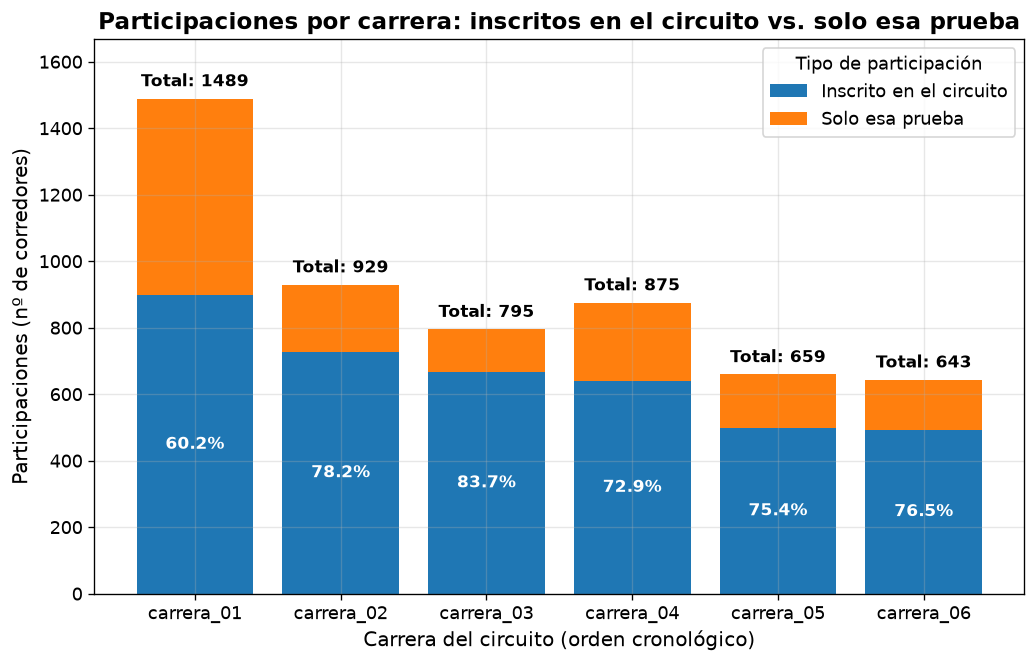

Grafica 1 guardada en: /home/carlosmaronoovies/sistemas_big_data/p2-coruna-corre/output/figuras/d01_cruce_inscritos_por_carrera.png


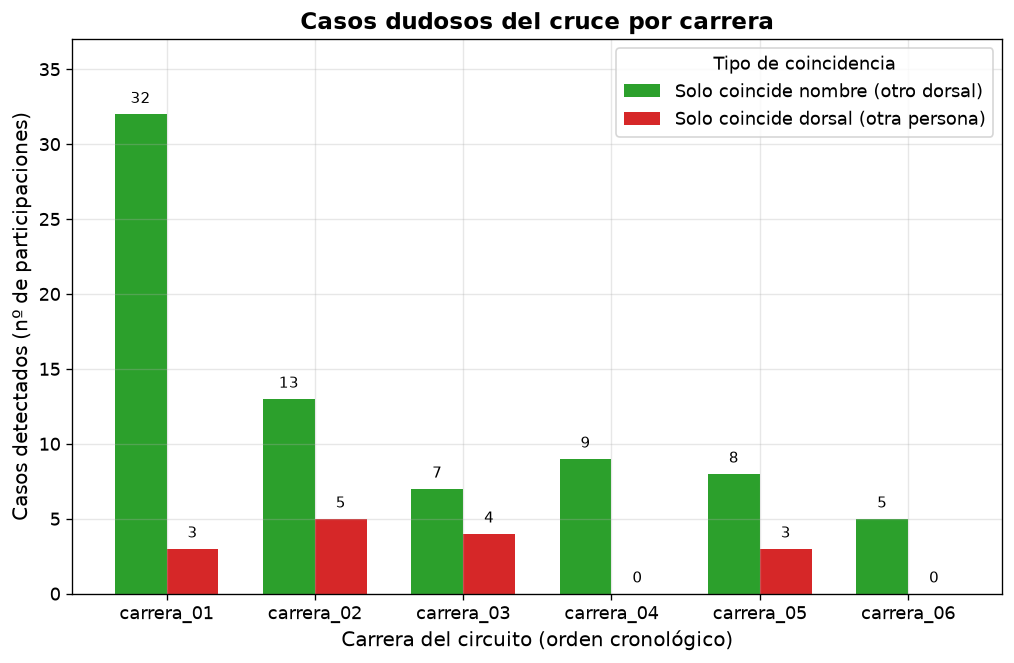

Grafica 2 guardada en: /home/carlosmaronoovies/sistemas_big_data/p2-coruna-corre/output/figuras/d01_casos_dudosos_cruce.png


In [ ]:
# --- GRAFICA 1: Inscritos frente a corredores solo de esa prueba (barras apiladas) ---
figura_inscritos, eje_inscritos = plt.subplots()

nombres_carreras = tabla_resumen_cruce["carrera_id"]
cantidad_inscritos = tabla_resumen_cruce["inscritos_true"]
cantidad_no_inscritos = tabla_resumen_cruce["inscritos_false"]

# Ponemos los inscritos abajo y encima apilamos los que corrieron solo esa prueba
eje_inscritos.bar(
    nombres_carreras,
    cantidad_inscritos,
    label="Inscrito en el circuito",
    color=PALETA_COLORES[0],
)
eje_inscritos.bar(
    nombres_carreras,
    cantidad_no_inscritos,
    bottom=cantidad_inscritos,
    label="Solo esa prueba",
    color=PALETA_COLORES[1],
)

# Ponemos el % en blanco dentro de la barra azul y el total de corredores arriba
for posicion, fila in enumerate(tabla_resumen_cruce.itertuples(index=False)):
    eje_inscritos.text(
        posicion,
        fila.inscritos_true / 2,
        f"{fila.porcentaje_inscritos:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontsize=10,
        fontweight="bold",
    )
    # Ponemos el total arriba de la barra en negrita para que se lea bien
    eje_inscritos.text(
        posicion,
        fila.total + 25,
        f"Total: {fila.total}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

eje_inscritos.set_title("Participaciones por carrera: inscritos en el circuito vs. solo esa prueba")
eje_inscritos.set_xlabel("Carrera del circuito (orden cronologico)")
eje_inscritos.set_ylabel("Participaciones (nº de corredores)")
eje_inscritos.set_ylim(0, tabla_resumen_cruce["total"].max() * 1.12)
eje_inscritos.legend(title="Tipo de participacion")

ruta_grafica_inscritos = guardar_figura(figura_inscritos, "d01_cruce_inscritos_por_carrera.png")
plt.show()
print("Grafica 1 guardada en:", ruta_grafica_inscritos.relative_to(ruta_raiz))


# --- GRAFICA 2: Casos dudosos por carrera (barras agrupadas lado a lado) ---
figura_dudosos, eje_dudosos = plt.subplots()

posiciones = list(range(len(tabla_resumen_cruce)))
ancho_barra = 0.35

# Movemos una barra un poco a la izquierda y la otra a la derecha para que no se pisen
posiciones_izquierda = [posicion - ancho_barra / 2 for posicion in posiciones]
posiciones_derecha = [posicion + ancho_barra / 2 for posicion in posiciones]

eje_dudosos.bar(
    posiciones_izquierda,
    tabla_resumen_cruce["solo_nombre"],
    width=ancho_barra,
    label="Solo coincide nombre (otro dorsal)",
    color=PALETA_COLORES[2],
)
eje_dudosos.bar(
    posiciones_derecha,
    tabla_resumen_cruce["solo_dorsal"],
    width=ancho_barra,
    label="Solo coincide dorsal (otra persona)",
    color=PALETA_COLORES[3],
)

# Ponemos el numero exacto encima de cada barra porque son cantidades pequenas
for pos_izq, pos_der, fila in zip(
    posiciones_izquierda,
    posiciones_derecha,
    tabla_resumen_cruce.itertuples(index=False),
):
    eje_dudosos.text(
        pos_izq, fila.solo_nombre + 0.5, str(fila.solo_nombre), ha="center", va="bottom", fontsize=9
    )
    eje_dudosos.text(
        pos_der, fila.solo_dorsal + 0.5, str(fila.solo_dorsal), ha="center", va="bottom", fontsize=9
    )

eje_dudosos.set_title("Casos dudosos del cruce por carrera")
eje_dudosos.set_xlabel("Carrera del circuito (orden cronologico)")
eje_dudosos.set_ylabel("Casos detectados (nº de participaciones)")
eje_dudosos.set_xticks(posiciones)
eje_dudosos.set_xticklabels(nombres_carreras)
eje_dudosos.set_ylim(0, tabla_resumen_cruce["solo_nombre"].max() + 5)
eje_dudosos.legend(title="Tipo de coincidencia")

ruta_grafica_dudosos = guardar_figura(figura_dudosos, "d01_casos_dudosos_cruce.png")
plt.show()
print("Grafica 2 guardada en:", ruta_grafica_dudosos.relative_to(ruta_raiz))

## Conclusiones finales

- **Descarga reproducible (`src/inscritos.py`):** las 94 paginas de inscritos se guardan en cache en `datos/raw/inscritos/`, una segunda ejecucion hace **0 peticiones nuevas** y `inscritos.csv` cuadra exactamente con los **2.345 inscritos** anunciados por la web (100 % confirmados y sin fechas vacias).
- **Calidad de `inscritos.csv`:** se detecto **1 dorsal repetido en 3 personas distintas** y **4 nombres normalizados repetidos** (2 veces cada uno), lo que justifica no cruzar usando un unico campo a ciegas.
- **Cruce de las 6 carreras oficiales (`src/cruce.py`):** sobre **5.390 participaciones** (anteriores a `FECHA_CORTE = 2026-11-22`), **3.915 (72,63 %)** son inscritos del circuito y **1.475 (27,37 %)** corrieron solo esa prueba. La primera carrera (`carrera_01`) concentra el mayor numero de corredores puntuales y casi la mitad de los casos de `solo_nombre` (32 de 74).
- **Criterio validado y privacidad:** `marcar_inscritos()` entrega la columna oficial `inscrito_circuito` del contrato (`True` para `ambos` y `solo_nombre`, `False` para `solo_dorsal` y `ninguno`), lista para integrarse tanto con los CSV base como con los `carrera_XX_limpia.csv` de Persona B, sin exponer nunca nombres ni dorsales.